<a href="https://colab.research.google.com/github/tvml/ml2627/blob/master/codici/overfitting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Overfitting e selezione del modello: un esperimento con la regressione polinomiale

Questo notebook illustra sperimentalmente il fenomeno dell'**overfitting**, in particolare nel caso della regressione lineare. Prima di guardare il codice, conviene richiamare il quadro concettuale in cui l'esperimento si colloca.

## Il problema

Nelle note sui fondamenti abbiamo visto che l'apprendimento supervisionato consiste nello scegliere, all'interno di una classe di ipotesi $\mathcal{H}$, un predittore $h$ con **rischio atteso** piccolo, cioè con un errore medio piccolo su *nuovi* elementi estratti dalla stessa distribuzione che ha generato i dati. Il rischio atteso non è calcolabile, perché la distribuzione è ignota: ciò che possiamo calcolare è il **rischio empirico** sul training set, e l'algoritmo di apprendimento (qui, i minimi quadrati) sceglie il predittore che lo minimizza.

Il punto cruciale è che il rischio empirico del predittore appreso è una stima **ottimistica** del suo rischio atteso: i parametri sono stati scelti proprio per adattarsi a *quei* dati, rumore compreso. Quanto più la classe di ipotesi è flessibile, tanto più il predittore può adattarsi ai dettagli casuali del training set, e tanto più grande può diventare la distanza tra errore di training ed errore su dati nuovi. Questo è l'**overfitting**: il modello riproduce il rumore del training set invece del segnale sottostante, e generalizza male.

## Il setting dell'esperimento

Seguiamo lo stesso schema dell'esempio dell'onda sinusoidale delle note:

- i dati sono generati da una funzione $f(x)$, *ignota* al learner, a cui si aggiunge rumore gaussiano: $t = f(x) + \varepsilon$. Siamo quindi nel caso **probabilistico** (FP) delle note: a parità di $x$, il target può variare, e la parte di errore dovuta a $\varepsilon$ è **irriducibile**;
- il modello è un **polinomio di grado $d$**, cioè un modello lineare nelle funzioni base $\phi_j(x)=x^j$, $j=0,\ldots,d$: lineare nei parametri, anche se non lineare in $x$;
- i parametri sono stimati con le **equazioni normali** $\overline{\mathbf{w}}^* = (\overline{\mathbf{X}}^T\overline{\mathbf{X}})^{-1}\overline{\mathbf{X}}^T\mathbf{t}$, che minimizzano la somma dei quadrati dei residui (equivalentemente, che danno la stima di massima verosimiglianza sotto rumore gaussiano);
- la qualità del modello viene misurata su un **test set** generato dallo stesso processo ma indipendente dal training set, che fornisce una stima non distorta del rischio atteso.

Facendo variare il grado $d$ osserveremo le due curve tipiche: l'errore di training che decresce monotonamente con $d$, e l'errore di test che prima decresce e poi cresce.

## Preparazione dell'ambiente

Le prime celle importano le librerie e impostano lo stile dei grafici; non hanno contenuto concettuale. `scipy.stats` viene usato per generare i dati casuali (distribuzione uniforme per gli input, gaussiana per il rumore), `numpy` per l'algebra lineare, `pandas` per raccogliere i risultati in una tabella.

In [23]:
from IPython.display import Image
import warnings
warnings.filterwarnings('ignore')


%matplotlib inline

In [24]:
import scipy as sc
import scipy.stats as stats
import numpy as np
import pandas as pd

La cella seguente configura l'aspetto dei grafici (font, dimensioni, palette di colori). La mappa di colori viene ottenuta con `plt.get_cmap`: la funzione `cm.get_cmap` della versione originale è stata rimossa nelle versioni recenti di matplotlib (dalla 3.9).

In [25]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib import cm

plt.style.use('fivethirtyeight')

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.serif'] = 'Ubuntu'
plt.rcParams['font.monospace'] = 'Ubuntu Mono'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['axes.titlesize'] = 10
plt.rcParams['xtick.labelsize'] = 8
plt.rcParams['ytick.labelsize'] = 8
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.titlesize'] = 12
plt.rcParams['image.cmap'] = 'jet'
plt.rcParams['image.interpolation'] = 'none'
plt.rcParams['figure.figsize'] = (16, 8)
plt.rcParams['lines.linewidth'] = 2
plt.rcParams['lines.markersize'] = 8

colors = ['xkcd:pale orange', 'xkcd:sea blue', 'xkcd:pale red', 'xkcd:sage green', 'xkcd:terra cotta', 'xkcd:dull purple', 'xkcd:teal', 'xkcd:goldenrod', 'xkcd:cadet blue', 
          'xkcd:scarlet']
cmap_big = plt.get_cmap('Spectral', 512)
cmap = mcolors.ListedColormap(cmap_big(np.linspace(0.7, 0.95, 256)))

bbox_props = dict(boxstyle="round,pad=0.3", fc=colors[0], alpha=.5)

## La funzione da apprendere

Definiamo la funzione $f(x)=\sin(x)\cos^2(x)$, che genera i dati. Nella realtà questa funzione è **sconosciuta**: il learner vede soltanto i punti del training set, e il suo obiettivo è ricostruire $f$ (più precisamente, la media condizionata $\mathbb{E}[t\mid x]=f(x)$, che è il predittore di Bayes sotto loss quadratica) a partire da osservazioni rumorose. Qui la conosciamo solo perché siamo noi a simulare il processo di generazione dei dati, il che ci permette di confrontare il modello appreso con la "verità".

In [26]:
def f(x):
    return np.sin(x)*(np.cos(x))**2

## Il rumore

La funzione `p` associa a ogni valore $x$ un target $t = f(x)+\varepsilon$, con $\varepsilon\sim\mathcal{N}(0,\sigma^2)$. Si noti che il parametro `scale` di `stats.norm` è la **deviazione standard**: con `scale=0.1` si ha $\sigma=0.1$, quindi varianza $\sigma^2=0.01$ (non $0.1$).

Questo è esattamente il modello a rumore additivo gaussiano: la distribuzione condizionata $p(t\mid x)$ è una gaussiana centrata in $f(x)$ con varianza costante. Ne seguono due conseguenze importanti per l'esperimento:

- anche il predittore perfetto $h=f$ avrebbe un errore quadratico medio pari a $\sigma^2$ sul test set: è l'**errore irriducibile**, e nessun modello può scendere sotto questa soglia (in media) su dati nuovi;
- un errore di training molto più piccolo di $\sigma$ è un campanello d'allarme: significa che il modello sta "spiegando" anche il rumore, che per definizione non è prevedibile.

In [27]:
def p(r):
    return [stats.norm.rvs(loc=f(x), scale=0.1, size=1) for x in r]

## Training set e test set

Usiamo $30$ punti per il training e $30$ per il test. Il numero di elementi del training set è un parametro importante: la tendenza all'overfitting dipende dal **rapporto** tra i gradi di libertà del modello (qui, $d+1$ coefficienti) e la quantità di informazione nei dati (qui, $n=30$ punti). Con più dati, lo stesso polinomio avrebbe meno spazio per seguire il rumore.

In [28]:
n_train = 30
n_test = 30

Gli input del training set sono estratti uniformemente nell'intervallo $[-2,2]$ (`loc=-2`, `scale=4`), e i target sono ottenuti applicando la funzione `p`. I vettori vengono rimodellati come colonne (`reshape(-1,1)`), come richiesto dalle operazioni matriciali successive.

In [29]:
x_train = stats.uniform.rvs(size=n_train, loc=-2, scale=4).reshape(-1,1)
y_train = np.array(p(x_train)).reshape(-1,1)

Il test set è generato **dallo stesso processo**, ma in modo indipendente. Questa è la condizione che rende l'errore sul test set una stima non distorta del rischio atteso: il test set non deve mai essere usato per scegliere i parametri. Se lo usassimo anche per scegliere il grado $d$, come faremo più avanti, la stima diventerebbe a sua volta ottimistica; in un'applicazione reale servirebbe un terzo insieme (o la cross-validation) per la selezione del modello, lasciando il test set alla valutazione finale.

In [30]:
x_test = stats.uniform.rvs(size=n_test, loc=-2, scale=4).reshape(-1,1)
y_test = np.array(p(x_test)).reshape(-1,1)

Il grafico mostra la funzione $f$ (la curva continua) e i due dataset. I punti si dispongono attorno alla curva, con uno scarto dovuto al rumore: il compito del modello è recuperare la curva, non passare per i punti.

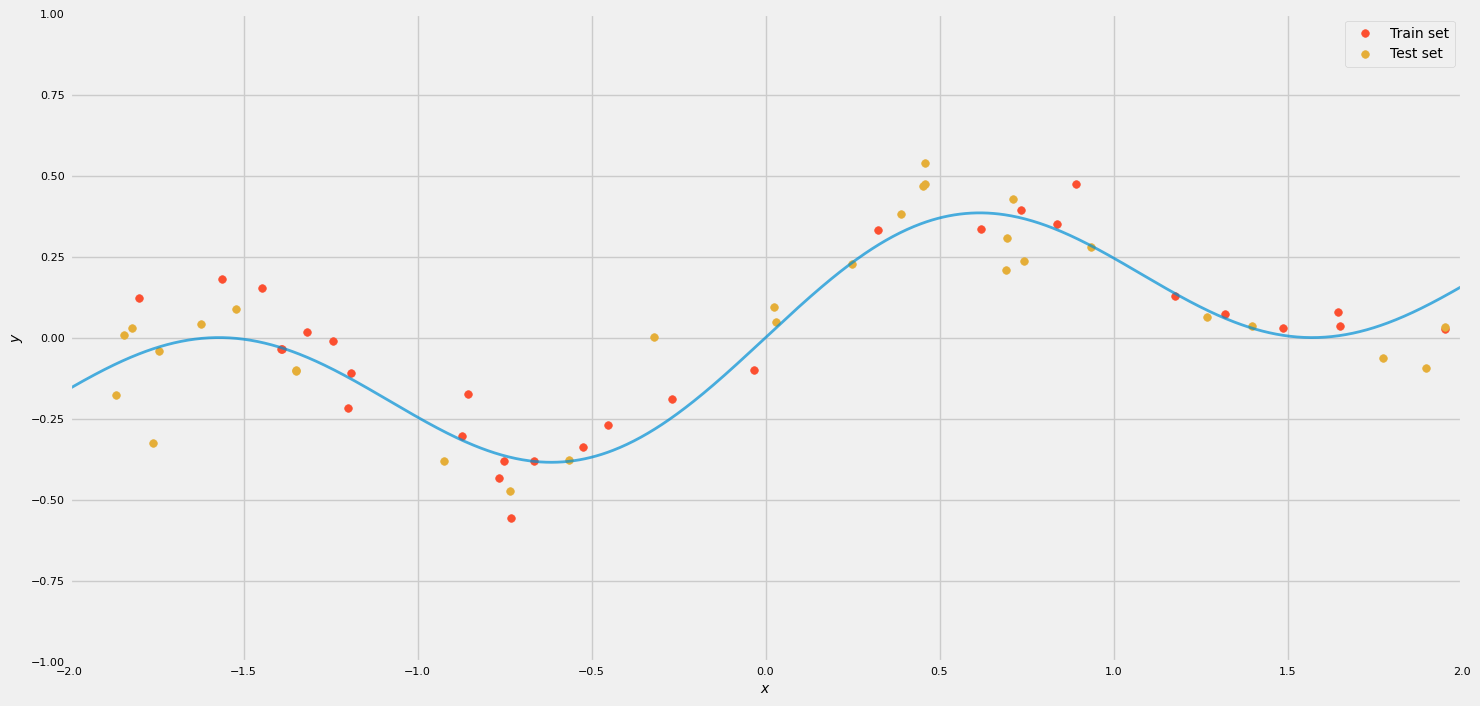

In [31]:
fig, ax = plt.subplots(figsize=(16, 8))
x = np.linspace(-2, 2, 1000)
plt.plot(x, f(x), linewidth=2, alpha = .7)
plt.scatter(x_train, y_train, s=30, color='C1', label='Train set')
plt.scatter(x_test, y_test, s=30, color='C2', label='Test set')
plt.xlim(-2, 2)
plt.ylim(-1,1)
plt.xlabel('$x$')
plt.ylabel(r'$y$')
plt.legend()
plt.show()

## Il modello: regressione polinomiale

Un polinomio di grado $d$,
$$h(x;\boldsymbol\theta)=\theta_0+\theta_1x+\theta_2x^2+\cdots+\theta_dx^d,$$
è un modello lineare nelle **funzioni base** $\phi_j(x)=x^j$ (note sulla regressione lineare, *Basis Functions*): la trasformazione $x\mapsto(1,x,x^2,\ldots,x^d)$ porta l'input in uno spazio di dimensione $d+1$, in cui il modello è un semplice prodotto scalare. Il grado $d$ è quindi una scelta di **rappresentazione**, e controlla direttamente la flessibilità della classe di ipotesi.

La funzione `predictions` valuta il polinomio con coefficienti `theta` nei punti `x`. Poiché `np.polyval` si aspetta i coefficienti in ordine decrescente di grado, mentre `theta` li contiene in ordine crescente ($\theta_0,\theta_1,\ldots$), il vettore viene invertito con `theta[::-1]`.

In [32]:
def predictions(theta, x):
    return np.polyval(theta[::-1],x)

## La misura dell'errore

La funzione `cost` calcola
$$\sqrt{\frac{1}{2n}\sum_{i=1}^n\bigl(t_i-h(x_i)\bigr)^2},$$
cioè, a meno del fattore $1/\sqrt2$, la **radice dell'errore quadratico medio** $E_{\mathrm{RMS}}=\sqrt{\frac1n\sum_i(t_i-h(x_i))^2}$ introdotta nelle note. Il fattore costante non cambia nessuna delle conclusioni (sposta tutte le curve dello stesso fattore), ma va tenuto presente se si vogliono confrontare i valori con la deviazione standard del rumore: per un modello perfetto ci aspetteremmo $E_{\mathrm{RMS}}\approx\sigma=0.1$, cioè un valore di `cost` attorno a $0.1/\sqrt2\approx0.07$.

La radice quadrata riporta l'errore sulla **scala del target**, il che rende i valori direttamente interpretabili. Come indica la firma della funzione, la stessa misura si calcola sul training set o sul test set: nel primo caso è il rischio empirico (a meno di trasformazioni monotone), nel secondo una stima del rischio atteso.

In [12]:
def cost(theta, x, t):
    n = x.shape[0]
    y = predictions(theta,x)
    return round(np.sqrt(np.sum((t-y)**2)/float(2*n)), 4)

## Un valore del grado fornisce un modello

Iniziamo assegnando un valore $d$ del grado, definendo quindi un modello lineare con $d+1$ coefficienti da stimare con $30$ punti.

In [13]:
degree = 6

## La matrice di design

La cella costruisce la **matrice di design aumentata** $\overline{\mathbf{X}}$ delle note: una colonna di uni (che corrisponde al termine costante $\theta_0$, il bias) seguita dalle colonne $x, x^2,\ldots,x^d$, ottenute moltiplicando ripetutamente per $x$. La riga $i$-esima è il vettore delle funzioni base valutate in $x_i$, $(1,x_i,x_i^2,\ldots,x_i^d)$. Una matrice di questo tipo è detta matrice di **Vandermonde**.

In [14]:
X = np.ones(n_train).reshape(-1,1)
Z = x_train
for i in range(degree):
    X = np.column_stack((X, Z))
    Z = Z*x_train

## Le equazioni normali

I coefficienti ottimi si ottengono con le equazioni normali,
$$\boldsymbol\theta^*=(\overline{\mathbf{X}}^T\overline{\mathbf{X}})^{-1}\overline{\mathbf{X}}^T\mathbf{t},$$
che danno in un solo passo, senza iterazioni, il minimo globale della somma dei quadrati dei residui (che è una funzione convessa dei parametri, perché il modello è lineare in essi).

**Osservazione numerica.** Calcolare esplicitamente l'inversa di $\overline{\mathbf{X}}^T\overline{\mathbf{X}}$ è sconsigliato in pratica: le colonne di una matrice di Vandermonde sono fortemente correlate (su $[-2,2]$, $x^{10}$ e $x^{12}$ hanno andamenti molto simili), e per gradi elevati la matrice $\overline{\mathbf{X}}^T\overline{\mathbf{X}}$ diventa quasi singolare, cioè **mal condizionata**. Piccoli errori di arrotondamento producono allora grandi errori nei coefficienti. Soluzioni più stabili sono `np.linalg.lstsq` o `np.linalg.solve`; la regolarizzazione ridge, che aggiunge $\lambda\mathbf{I}$ alla diagonale, risolve il problema anche dal punto di vista statistico. Per i gradi più alti dell'esperimento successivo, parte del comportamento osservato può dipendere anche da questi problemi numerici.

In [15]:
theta = np.dot(np.dot(np.linalg.inv(np.dot(X.T, X)) , X.T), y_train)

Calcoliamo l'errore sul training set e sul test set per il modello appena stimato.

In [16]:
c_train = cost(theta,x_train,y_train)
c_test = cost(theta,x_test,y_test)

Il grafico confronta il polinomio appreso (in rosso) con la funzione vera (tratteggiata). Con grado $6$ il modello ha abbastanza flessibilità per seguire l'andamento di $f$ nell'intervallo, e i due errori dovrebbero essere simili e vicini al livello del rumore: è una situazione di buon equilibrio. È utile ripetere l'esperimento modificando `degree` (per esempio $1$, $3$, $15$) e osservare come cambia la curva: con grado basso il modello è troppo rigido per seguire le oscillazioni (**underfitting**), con grado alto inizia a piegarsi per inseguire i singoli punti, specialmente vicino ai bordi dell'intervallo, dove i polinomi di grado elevato tendono a oscillare violentemente.

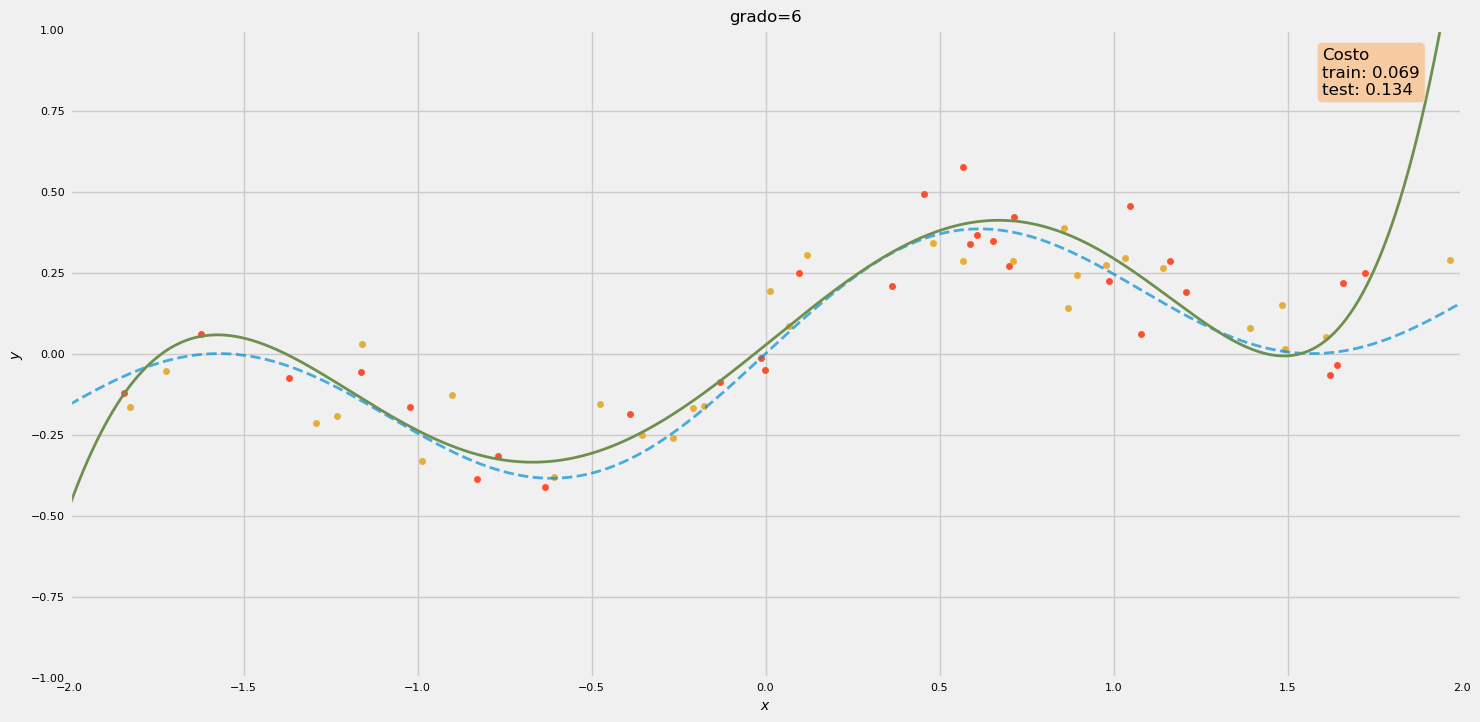

In [17]:
fig, ax = plt.subplots(figsize=(16, 8))
x = np.linspace(-2, 2, 1000)
plt.plot(x, f(x), lw=2, ls='dashed', alpha = .7)
plt.scatter(x_train, y_train, s=20, color='C1')
plt.scatter(x_test, y_test, s=20, color='C2')
plt.plot(x, predictions(theta,x), color='C3', linewidth=2, alpha=1)
plt.xlim(-2, 2)
plt.ylim(-1,1)
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.title('grado={0:d}'.format(degree), fontsize=12)
plt.text(0.9, 0.9, 'Costo\ntrain: {0:.3f}\ntest: {1:.3f}'.format(c_train, c_test), fontsize=12, 
         transform=ax.transAxes, bbox=bbox_props)
plt.show()

## Selezione del modello: errore al variare del grado

Ripetiamo ora la stima per tutti i gradi da $0$ a $19$, registrando per ciascuno l'errore di training e quello di test. Questa è una forma elementare di **model selection**: tra le classi di ipotesi $\mathcal{H}_0\subset\mathcal{H}_1\subset\cdots$ (polinomi di grado al più $d$), vogliamo scegliere quella che porta al rischio atteso minimo.

Le classi sono **annidate**: ogni polinomio di grado $d$ è anche un polinomio di grado $d+1$ (con l'ultimo coefficiente nullo). Ne segue che il minimo del rischio empirico non può crescere al crescere di $d$: l'errore di training è una funzione non crescente del grado. Per $d+1=n$ il polinomio può interpolare esattamente tutti i punti del training set, con errore di training nullo; qui $n=30$, e ci fermiamo poco prima.

In [18]:
maxdeg = 20
costs_train =  []  
costs_test =  [] 

Il ciclo ricostruisce, per ogni grado, la matrice di design, stima i coefficienti con le equazioni normali e calcola i due errori. Per $d=0$ la matrice ha una sola colonna di uni, e il modello è la costante pari alla media dei target.

In [19]:
for degree in range(0, maxdeg):
    X = np.ones(n_train).reshape(-1,1)
    Z = x_train
    for i in range(degree):
        X = np.column_stack((X, Z))
        Z=Z*x_train
    
    theta = np.dot(np.dot(np.linalg.inv(np.dot(X.T, X)), X.T), y_train)
    
    costs_train.append(cost(theta,x_train,y_train))
    costs_test.append(cost(theta,x_test,y_test))

I risultati sono raccolti in un `DataFrame`, insieme al **rapporto** tra errore di test ed errore di training: un rapporto vicino a $1$ indica che l'errore di training è una stima affidabile di quello su dati nuovi; un rapporto molto maggiore di $1$ è il segno tipico dell'overfitting, cioè di una stima di training eccessivamente ottimistica.

In [20]:
df = pd.DataFrame()
df['train'] = costs_train
df['test'] = costs_test
df['ratio'] = df.test/df.train

## Le due curve

Il grafico mostra il comportamento descritto nelle note (*Overfitting and Model Selection*):

- **errore di training** (sopra): decresce al crescere del grado, perché un modello più flessibile si adatta ai punti del training set almeno altrettanto bene di uno più rigido;
- **errore di test** (sotto): per gradi bassi decresce, perché il modello acquista la flessibilità necessaria a catturare la struttura reale di $f$; superato un certo grado smette di migliorare e poi cresce, perché la flessibilità in eccesso viene usata per seguire il rumore del particolare training set, che non si ripete nel test set.

Il grado migliore corrisponde al **minimo dell'errore di test**. A sinistra di questo minimo il modello è in **underfitting** (troppo rigido, errore alto sia in training che in test); a destra è in **overfitting** (errore di training basso, errore di test alto).

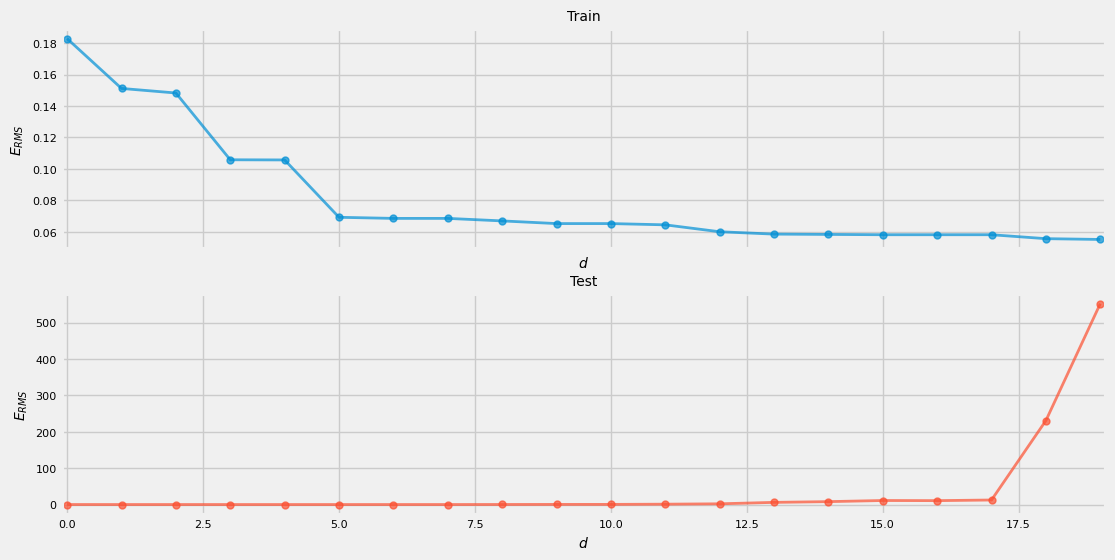

In [21]:
top = maxdeg
fig, axarr = plt.subplots(2, sharex=True, figsize=(12, 6))
axarr[0].plot(df.index[:top], df.train[:top], linewidth=2, alpha = .7, marker = 'o', markersize=5)
axarr[0].set_title('Train')
axarr[0].set_xlabel('$d$')
axarr[0].set_ylabel('$E_{RMS}$')
axarr[1].plot(df.index[:top], df.test[:top], linewidth=2, alpha = .7, marker = 'o', markersize=5, color='C1')
axarr[1].set_title('Test')
plt.xlim(-0.1, df.index[top-1]+.1)
axarr[1].set_xlabel('$d$')
axarr[1].set_ylabel('$E_{RMS}$')
plt.show()

## Il rapporto tra errore di test ed errore di training

Il rapporto rende evidente il **divario di generalizzazione**: per gradi bassi i due errori sono simili e il rapporto resta vicino a $1$; al crescere del grado l'errore di training continua a scendere mentre quello di test aumenta, e il rapporto cresce rapidamente. L'errore di training diventa quindi una stima sempre più ottimistica del rischio atteso, esattamente come previsto dalla discussione sull'ottimismo del rischio empirico nelle note sui fondamenti.

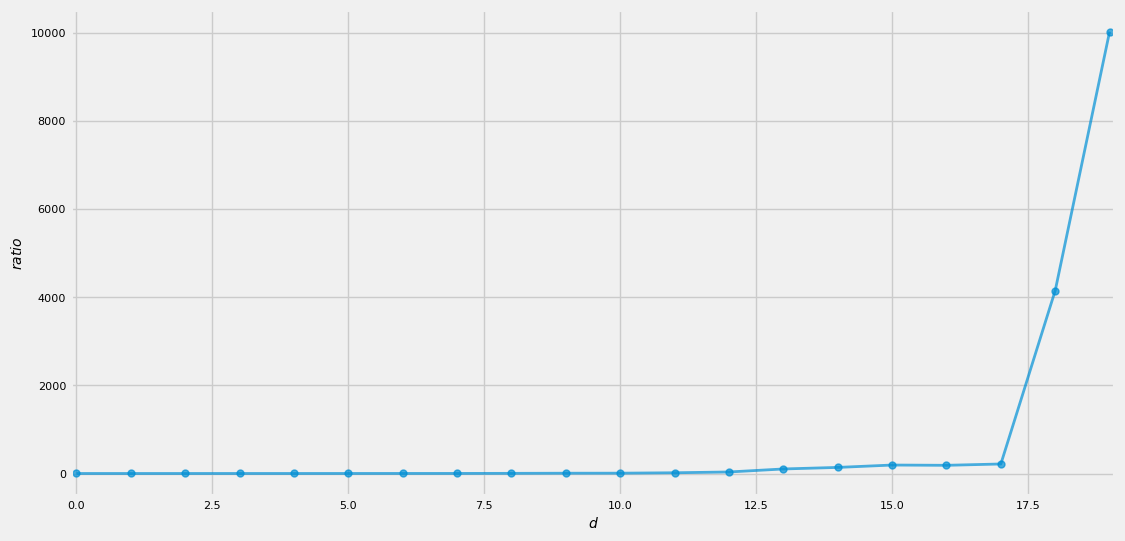

In [22]:
top = maxdeg
fig, ax = plt.subplots(figsize=(12, 6))
plt.plot(df.index[:top], df.ratio[:top], linewidth=2, alpha = .7, marker = 'o', markersize=5)
plt.xlim(-0.1, df.index[top-1]+.1)
plt.xlabel('$d$')
plt.ylabel(r'$ratio$')
plt.show()

## Lettura in termini di bias e varianza

Il comportamento osservato si interpreta con la **decomposizione bias–varianza** della loss quadratica (note sulla regressione lineare): l'errore atteso su un nuovo punto si scompone in
$$\text{rumore }(\sigma^2)\;+\;\text{bias}^2\;+\;\text{varianza}.$$

- Con grado basso il modello non è in grado di rappresentare $f$: qualunque sia il training set, la curva appresa resta lontana dalla funzione vera. È un errore **sistematico**, cioè un **bias** elevato, mentre la **varianza** è bassa (training set diversi producono curve simili).
- Con grado alto il modello può rappresentare bene $f$ in media (bias basso), ma la curva appresa dipende fortemente dal particolare campione di rumore: training set diversi produrrebbero polinomi molto diversi. È la **varianza** a dominare.
- Il termine di rumore $\sigma^2$ non dipende dal modello e non può essere eliminato: per questo l'errore di test non può scendere sotto il livello di $\sigma$, mentre l'errore di training, per gradi alti, può farlo, ed è proprio questo il segnale dell'overfitting.

## Come contrastare l'overfitting

Le note discutono tre strade, che è istruttivo sperimentare modificando il notebook:

1. **Più dati**: aumentando `n_train` (per esempio a $200$), lo stesso grado ha meno possibilità di seguire il rumore, e il minimo dell'errore di test si sposta verso gradi più alti.
2. **Una classe di ipotesi più piccola**: è ciò che facciamo scegliendo il grado al minimo dell'errore di test (o, più correttamente, di un errore di validazione).
3. **Regolarizzazione**: mantenere un grado alto ma penalizzare i coefficienti grandi. Con la regolarizzazione ridge la soluzione diventa
$$\boldsymbol\theta^*=(\lambda\mathbf{I}+\overline{\mathbf{X}}^T\overline{\mathbf{X}})^{-1}\overline{\mathbf{X}}^T\mathbf{t},$$
che si ottiene con una modifica di una sola riga nel calcolo di `theta`. Facendo variare $\lambda$ invece di $d$ si osservano curve analoghe a quelle viste qui: $\lambda$ grande porta all'underfitting, $\lambda$ piccolo all'overfitting, e il valore migliore sta in mezzo. Come visto nelle note, questa soluzione coincide con la media a posteriori della regressione lineare bayesiana con prior gaussiano, con $\lambda=\alpha/\beta$.

Infine, poiché i dati sono generati casualmente senza fissare un seme (`np.random.seed`), ogni esecuzione produce dataset diversi e curve leggermente diverse: rieseguire il notebook più volte è un modo semplice per rendersi conto della **variabilità** dell'errore di test, e quindi del fatto che anche la scelta del grado migliore è, essa stessa, soggetta a rumore.